# Lab 4: Regression Analysis with Regularization Techniques

**Name:** Anusha Sharma  
**Course:** MSCS 634 – Advanced Big Data and Data Mining  
**University:** University of the Cumberlands



**Objectives**


a. This laboratory experiment aims at developing and comparing Simple Linear Regression, Multiple Linear Regression, Polynomial Regression, Ridge Regression, and Lasso Regression on the basis of Diabetes data.

b. The following measures are used for evaluating the developed models: MAE, MSE, RMSE, and R².

**1. Dataset loading**

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

diabetes = load_diabetes(as_frame=True)

X = diabetes.data
y = diabetes.target

print("Dataset Shape:", X.shape)
print("\nFirst 5 Rows:")
display(X.head())

print("\nMissing Values:")
print(X.isnull().sum())

print("\nDataset Statistics:")
display(X.describe())


Dataset Shape: (442, 10)

First 5 Rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641



Missing Values:
age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64

Dataset Statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


**1.1** **Visualization of the data distribution**

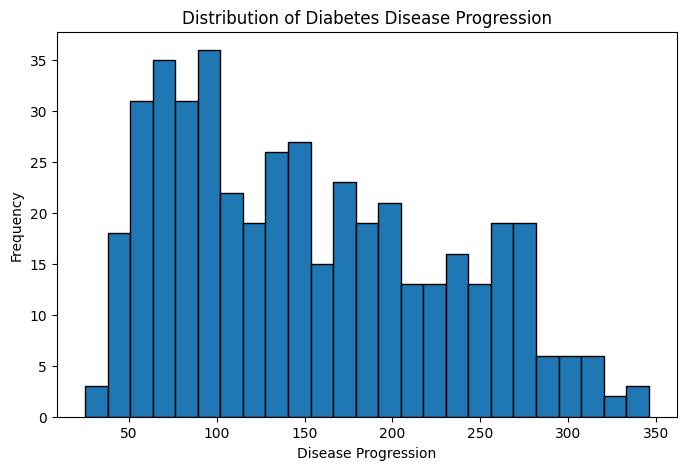

In [2]:

plt.figure(figsize=(8, 5))
plt.hist(y, bins=25, edgecolor="black")
plt.title("Distribution of Diabetes Disease Progression")
plt.xlabel("Disease Progression")
plt.ylabel("Frequency")
plt.show()


**2.** **Simple Linear Regression**

In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

results = []

def evaluate_model(name, model, X_tr, X_te):
    train_pred = model.predict(X_tr)
    test_pred = model.predict(X_te)

    metrics = {
        "Model": name,
        "MAE": mean_absolute_error(y_test, test_pred),
        "MSE": mean_squared_error(y_test, test_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "R2": r2_score(y_test, test_pred),
        "Train R2": r2_score(y_train, train_pred)
    }
    results.append(metrics)
    return test_pred

simple_model = LinearRegression()
simple_model.fit(X_train[["bmi"]], y_train)

simple_pred = evaluate_model(
    "Simple Linear",
    simple_model,
    X_train[["bmi"]],
    X_test[["bmi"]]
)

display(pd.DataFrame(results).round(3))


,Model,MAE,MSE,RMSE,R2,Train R2
0,Simple Linear,52.26,4061.826,63.732,0.233,0.366


**2.1** **Visualization**

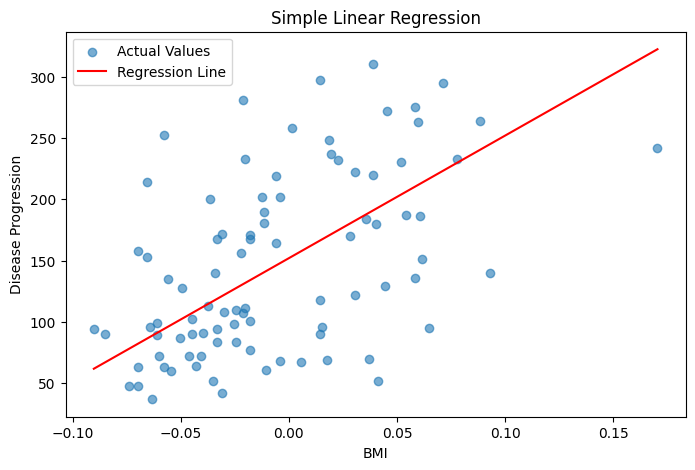

In [4]:

plt.figure(figsize=(8, 5))
plt.scatter(X_test["bmi"], y_test, alpha=0.6,
            label="Actual Values")

order = np.argsort(X_test["bmi"].values)

plt.plot(
    X_test["bmi"].values[order],
    simple_pred[order],
    color="red",
    label="Regression Line"
)

plt.xlabel("BMI")
plt.ylabel("Disease Progression")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()


**3. Multiple Linear Regression**

,Model,MAE,MSE,RMSE,R2,Train R2
0,Simple Linear,52.260,4061.826,63.732,0.233,0.366
1,Multiple Linear,42.794,2900.194,53.853,0.453,0.528


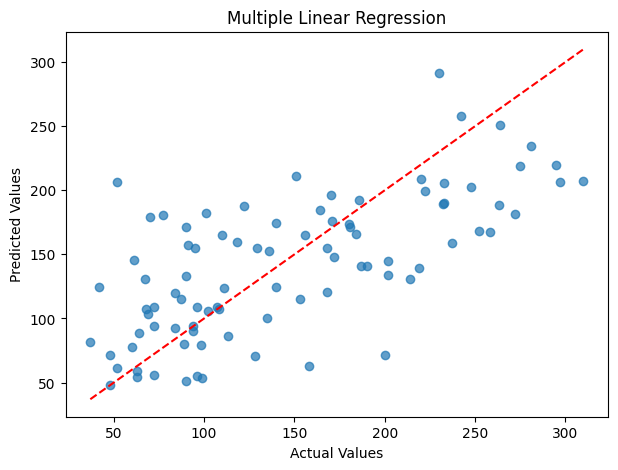

In [5]:

multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

multiple_pred = evaluate_model(
    "Multiple Linear",
    multiple_model,
    X_train,
    X_test
)

display(pd.DataFrame(results).round(3))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, multiple_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Multiple Linear Regression")
plt.show()


**4. Polynomial Regression**

In [6]:

poly_models = {}

for degree in [2, 3, 4]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(X_train[["bmi"]], y_train)

    predictions = evaluate_model(
        f"Polynomial Degree {degree}",
        model,
        X_train[["bmi"]],
        X_test[["bmi"]]
    )

    poly_models[degree] = model

display(pd.DataFrame(results).round(3))


,Model,MAE,MSE,RMSE,R2,Train R2
0,Simple Linear,52.260,4061.826,63.732,0.233,0.366
1,Multiple Linear,42.794,2900.194,53.853,0.453,0.528
2,Polynomial Degree 2,52.384,4085.025,63.914,0.229,0.367
3,Polynomial Degree 3,52.181,4064.443,63.753,0.233,0.367
4,Polynomial Degree 4,52.376,4226.145,65.009,0.202,0.370


**4.1 Polynomial visualization**

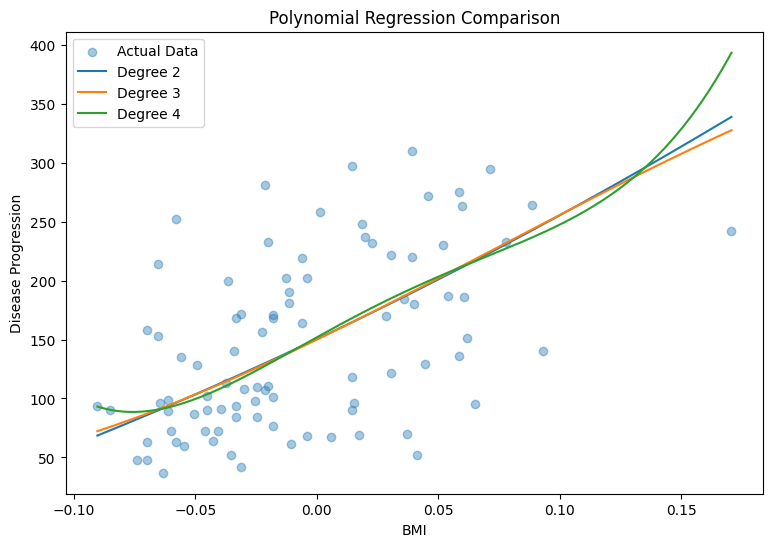

In [7]:

bmi_range = np.linspace(
    X["bmi"].min(), X["bmi"].max(), 200
)
bmi_grid = pd.DataFrame({"bmi": bmi_range})

plt.figure(figsize=(9, 6))
plt.scatter(X_test["bmi"], y_test, alpha=0.4,
            label="Actual Data")

for degree, model in poly_models.items():
    plt.plot(
        bmi_range,
        model.predict(bmi_grid),
        label=f"Degree {degree}"
    )

plt.xlabel("BMI")
plt.ylabel("Disease Progression")
plt.title("Polynomial Regression Comparison")
plt.legend()
plt.show()


**5. Ridge and Lasso Regression**

In [8]:

ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)
ridge_model.fit(X_train, y_train)

ridge_pred = evaluate_model(
    "Ridge",
    ridge_model,
    X_train,
    X_test
)

lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=1.0, max_iter=20000)
)
lasso_model.fit(X_train, y_train)

lasso_pred = evaluate_model(
    "Lasso",
    lasso_model,
    X_train,
    X_test
)

display(pd.DataFrame(results).round(3))


,Model,MAE,MSE,RMSE,R2,Train R2
0,Simple Linear,52.260,4061.826,63.732,0.233,0.366
1,Multiple Linear,42.794,2900.194,53.853,0.453,0.528
2,Polynomial Degree 2,52.384,4085.025,63.914,0.229,0.367
3,Polynomial Degree 3,52.181,4064.443,63.753,0.233,0.367
4,Polynomial Degree 4,52.376,4226.145,65.009,0.202,0.370
5,Ridge,42.812,2892.015,53.777,0.454,0.528
6,Lasso,42.803,2824.568,53.147,0.467,0.523


**5.1 Compare alpha values**

,Model,Alpha,Test R2,RMSE
0,Ridge,0.01,0.453,53.852
1,Lasso,0.01,0.453,53.836
2,Ridge,0.10,0.453,53.843
3,Lasso,0.10,0.456,53.709
4,Ridge,1.00,0.454,53.777
5,Lasso,1.00,0.467,53.147
6,Ridge,10.00,0.457,53.626
7,Lasso,10.00,0.446,54.165
8,Ridge,100.00,0.461,53.462
9,Lasso,100.00,-0.012,73.222


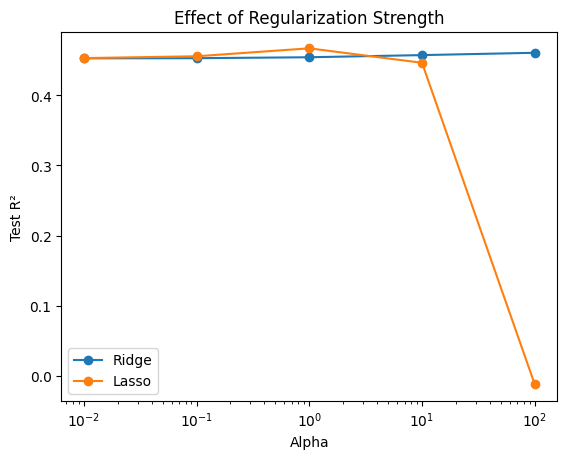

In [9]:

alpha_results = []

for alpha in [0.01, 0.1, 1, 10, 100]:
    for name, estimator in [
        ("Ridge", Ridge(alpha=alpha)),
        ("Lasso", Lasso(alpha=alpha, max_iter=20000))
    ]:
        model = make_pipeline(StandardScaler(), estimator)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        alpha_results.append({
            "Model": name,
            "Alpha": alpha,
            "Test R2": r2_score(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred))
        })

alpha_df = pd.DataFrame(alpha_results)
display(alpha_df.round(3))

for name in ["Ridge", "Lasso"]:
    subset = alpha_df[alpha_df["Model"] == name]
    plt.plot(subset["Alpha"], subset["Test R2"],
             marker="o", label=name)

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("Test R²")
plt.title("Effect of Regularization Strength")
plt.legend()
plt.show()


**6. Model comparison and analysis**

,Model,MAE,MSE,RMSE,R2,Train R2
6,Lasso,42.803,2824.568,53.147,0.467,0.523
5,Ridge,42.812,2892.015,53.777,0.454,0.528
1,Multiple Linear,42.794,2900.194,53.853,0.453,0.528
0,Simple Linear,52.260,4061.826,63.732,0.233,0.366
3,Polynomial Degree 3,52.181,4064.443,63.753,0.233,0.367
2,Polynomial Degree 2,52.384,4085.025,63.914,0.229,0.367
4,Polynomial Degree 4,52.376,4226.145,65.009,0.202,0.370


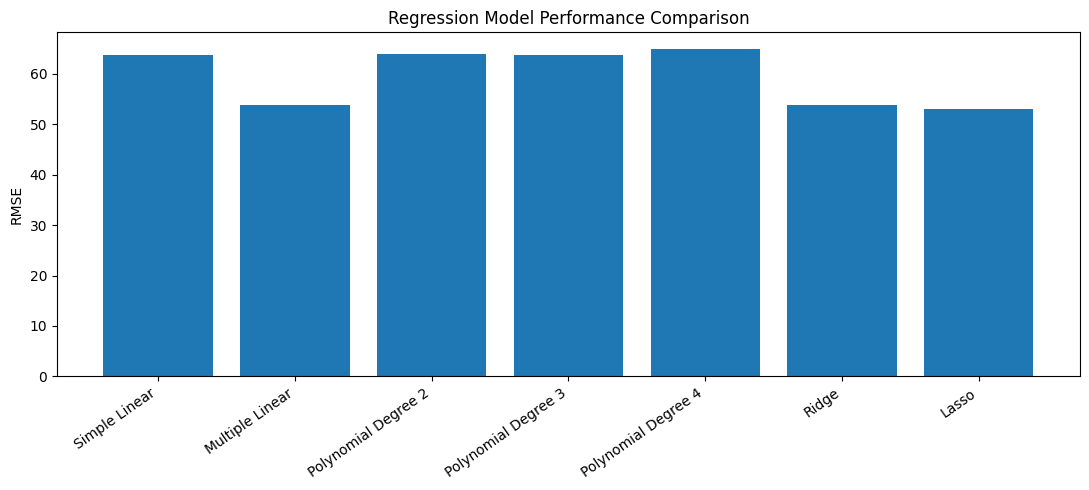

Best Model Based on Test RMSE: Lasso


In [10]:

comparison_df = pd.DataFrame(results)

display(
    comparison_df.sort_values("RMSE").round(3)
)

plt.figure(figsize=(11, 5))
plt.bar(comparison_df["Model"], comparison_df["RMSE"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("RMSE")
plt.title("Regression Model Performance Comparison")
plt.tight_layout()
plt.show()

best_model = comparison_df.loc[
    comparison_df["RMSE"].idxmin(), "Model"
]

print("Best Model Based on Test RMSE:", best_model)


**7. Conclusion**

In this lab, there have been five regressions used for the Diabetes dataset: Simple Linear Regression, Multiple Linear Regression, Polynomial Regression, Ridge Regression, and Lasso Regression.

These algorithms have been compared based on MAE, MSE, RMSE, and R². Simple Linear Regression took BMI as an independent variable, while Multiple Linear Regression used all ten available features. Polynomial Regression showed how the increase of model complexity may affect training and testing results.

Ridge and Lasso Regression have been performed to see how the regularization may affect these models. Ridge Regression regularizes by reducing large weights, while Lasso Regression may set some of the weights equal to zero, which can help with feature selection. Various alpha values have been used to see how the regularization will affect the algorithm performance.

According to the final comparison table, the model with the lowest testing RMSE is considered the best performing model in this case.